# Demo - Creating Vector Embeddings with Gemini Embedding Model

Import the required packages

In [2]:
from google import genai
from google.genai import types
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import display

Set the API Key

In [3]:
from google.colab import userdata

api_key = userdata.get("GOOGLE_API_KEY")

if not api_key:
  raise RuntimeError(
      "GOOGLE_API_KEY not found. "
      "Add it via Colab -> 🔑 Secrets -> enable Notebook access."
  )

client = genai.Client(api_key=api_key)

Generate the Embeddings

In [4]:
texts = [
    "How do I write a Python function?",
    "How can I create a class in Java?",
    "Which smartphone has the best camera?",
    "What is the best Android phone?",
    "Turn off the lights.",
    "Switch the lights off.",
    "Apple released a new iPhone",
    "Apple is my favorite fruit.",
]

# By Default Dimension = 3072 but you can control dimentions using output_dimensionality=768, 1536

result = client.models.embed_content(
    model="gemini-embedding-001",
    contents=texts,
    config=types.EmbedContentConfig(task_type="SEMANTIC_SIMILARITY", outputDimensionality=768)
)

for text, embedding_obj in zip(texts, result.embeddings):
  embedding = embedding_obj.values
  print("Text:", text)
  print("Embedding length:", len(embedding))
  print("Embeddings:", embedding)
  print("-" * 50)

Text: How do I write a Python function?
Embedding length: 768
Embeddings: [-0.007334515, -0.006950146, 0.018683976, -0.04260659, -0.013810179, -0.02353132, 0.0017563101, 0.012470875, 0.03482735, 0.007981162, -0.021974491, -0.008932356, -0.03219012, 0.008530096, 0.13476881, -0.009113698, -0.023886729, 0.01596416, 0.005160837, -0.011251521, 0.0020869148, 0.015941188, -0.004785726, -0.020768173, -0.009616656, -0.015237897, 0.0153389685, 0.022661485, 0.036309812, -0.022520773, 0.0061276644, 0.02676682, 0.009503948, 0.015846258, -0.003522161, 0.013055647, 0.01262321, 0.005883274, 0.014447721, 0.04268203, -0.02048863, -0.008275668, 0.0029366165, -0.0018869105, 0.021970829, 0.005502179, -0.006817169, -0.022217361, -0.0030909744, 0.009136699, -0.00038050817, -0.0068712486, -0.011236744, -0.17840478, 0.008931584, -0.0010842282, -0.0068541258, 0.01222939, 0.0003866231, 0.0074349977, -0.023397373, 0.03202773, -0.033427857, -0.032966875, 0.004789494, -0.010730537, 0.03292936, -0.022680353, -0.0020

Create a 3x3 table to show the similarity matrix

In [7]:
df = pd.DataFrame(
    cosine_similarity([e.values for e in result.embeddings]),
    index=texts,
    columns=texts,
)
display(df)

,How do I write a Python function?,How can I create a class in Java?,Which smartphone has the best camera?,What is the best Android phone?,Turn off the lights.,Switch the lights off.,Apple released a new iPhone,Apple is my favorite fruit.
How do I write a Python function?,1.000000,0.792966,0.683139,0.692409,0.668049,0.664706,0.705784,0.692279
How can I create a class in Java?,0.792966,1.000000,0.697506,0.711553,0.667857,0.663003,0.697855,0.687971
Which smartphone has the best camera?,0.683139,0.697506,1.000000,0.917305,0.650889,0.655075,0.786774,0.697292
What is the best Android phone?,0.692409,0.711553,0.917305,1.000000,0.641943,0.644259,0.771029,0.700769
Turn off the lights.,0.668049,0.667857,0.650889,0.641943,1.000000,0.988772,0.661992,0.632479
Switch the lights off.,0.664706,0.663003,0.655075,0.644259,0.988772,1.000000,0.670917,0.631576
Apple released a new iPhone,0.705784,0.697855,0.786774,0.771029,0.661992,0.670917,1.000000,0.788904
Apple is my favorite fruit.,0.692279,0.687971,0.697292,0.700769,0.632479,0.631576,0.788904,1.000000


## Vistualise in 3D Using PCA

### What is PCA(Principal Component Analysis)?
PCA is a technique used to reduce the number of dimensions in data while keeping as much important information as possible.
In simple terms:
  - PCA compresses high-dimensional data into fewer dimensions so we can visualize or analyze it more easily.

Humans cannot visalize 768-dimensional space
So we use PCA to transform:
768 dimensions -> 3 dimensions



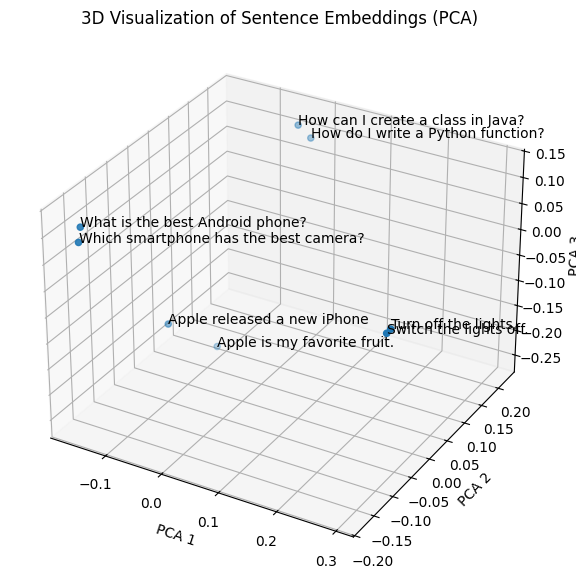

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA


# Convert embeddings to numpy matrix
embeddings = np.array([e.values for e in result.embeddings])

# Reduce dimensions: 768 -> 3
pca = PCA(n_components=3)
reduced = pca.fit_transform(embeddings)

df = pd.DataFrame(reduced, columns=["x","y","z"])
df["text"] = texts

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(df["x"], df["y"], df["z"])

for i, txt in enumerate(df["text"]):
  ax.text(df["x"][i], df["y"][i], df["z"][i], txt)

ax.set_title("3D Visualization of Sentence Embeddings (PCA)")
ax.set_xlabel("PCA 1")
ax.set_ylabel("PCA 2")
ax.set_zlabel("PCA 3")

plt.show()

In [10]:
import plotly.express as px

fig = px.scatter_3d(
    df,
    x="x",
    y="y",
    z="z",
    text="text",
    title="3D Embedding Visualization",
    height=800,
    width=1100
)

fig.show()